# 04 Modeling
Marvin Pearson, DSBA/HCIP-6156-U91, Fall 2026. Tracker tasks M01 to M07.

The target is (y = (30 - availability_30) / 30).For listings that are 'Unavailable' isn't the same as booked, it can also be a host block, so this is a proxy for occupancy.

`availability_30/60/90/365` never go into X.

In [7]:
# imports, Week 2 and Week 3 demo setup cells
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

## Load data
Typed loader copied from `data/README.md`

In [10]:
# typed loader from data/README.md section 4, from Dzmitry's loader in data/README.md section 4 (tracker M01 says use it)
PROCESSED_DIR = Path("data/processed")
if not PROCESSED_DIR.exists():
    PROCESSED_DIR = Path("../data/processed")
FIG_DIR = PROCESSED_DIR.parent.parent / "outputs" / "figures"

# 1. Listings Reload 
DATE_COLS_LISTINGS = [
    'last_scraped', 'host_since', 'calendar_last_scraped',
    'first_review', 'last_review',
    'rev_first_date_from_reviews', 'rev_last_date_from_reviews'
]
BOOL_COLS_LISTINGS = [
    'host_is_superhost', 'host_has_profile_pic', 'host_identity_verified',
    'is_location_exact', 'has_availability', 'requires_license',
    'instant_bookable', 'require_guest_profile_picture', 'require_guest_phone_verification'
]
INT_COLS_LISTINGS = [
    'walk_score', 'transit_score', 'bike_score', 'ws_population', 'ws_rank',
    'rev_count_from_reviews', 'rev_unique_reviewers'
]

dtypes_listings = {col: 'boolean' for col in BOOL_COLS_LISTINGS}
dtypes_listings.update({col: 'Int64' for col in INT_COLS_LISTINGS})

df_listings = pd.read_csv(
    PROCESSED_DIR / 'listings_clean.csv',
    parse_dates=DATE_COLS_LISTINGS,
    dtype=dtypes_listings
)

# 2. Calendar Reload 
DATE_COLS_CALENDAR = ['date']
BOOL_COLS_CALENDAR = ['available', 'is_holiday', 'is_event']
INT_COLS_CALENDAR = ['event_record_count']

dtypes_calendar = {col: 'boolean' for col in BOOL_COLS_CALENDAR}
dtypes_calendar.update({col: 'Int64' for col in INT_COLS_CALENDAR})

df_calendar = pd.read_csv(
    PROCESSED_DIR / 'calendar_clean.csv',
    parse_dates=DATE_COLS_CALENDAR,
    dtype=dtypes_calendar
)

print("listings shape:", df_listings.shape, "(expected (3818, 102))")
print("calendar shape:", df_calendar.shape, "(expected (1393570, 10))")
assert df_listings.shape == (3818, 102)
assert df_calendar.shape == (1393570, 10)

listings shape: (3818, 102) (expected (3818, 102))
calendar shape: (1393570, 10) (expected (1393570, 10))


## M01 - Target

In [11]:
# one row per listing, and what availability_30 looks like
# from: Week 2 Demo 1, tracker M01
df = df_listings.copy()

print("id unique (one row per listing):", df["id"].is_unique)
print("availability_30 dtype:", df["availability_30"].dtype)
print("availability_30 missing:", df["availability_30"].isna().sum())
print("availability_30 min / max:", df["availability_30"].min(), "/", df["availability_30"].max())
print("calendar_last_scraped values:", df["calendar_last_scraped"].dt.date.unique())

id unique (one row per listing): True
availability_30 dtype: int64
availability_30 missing: 0
availability_30 min / max: 0 / 30
calendar_last_scraped values: [datetime.date(2016, 1, 4)]


In [12]:
# the target, tracker M01 (target formula)
df["y"] = (30 - df["availability_30"]) / 30

print("y missing:", df["y"].isna().sum())
print("y min / max:", df["y"].min(), "/", df["y"].max())
print("y inside [0, 1]:", bool(df["y"].between(0, 1).all()))
print("y mean:", round(df["y"].mean(), 4), " median:", round(df["y"].median(), 4), " SD:", round(df["y"].std(), 4))
print("listings with y == 0 (fully available):", int((df["y"] == 0).sum()))
print("listings with y == 1 (fully unavailable):", int((df["y"] == 1).sum()))

y missing: 0
y min / max: 0.0 / 1.0
y inside [0, 1]: True
y mean: 0.4405  median: 0.3333  SD: 0.4058
listings with y == 0 (fully available): 981
listings with y == 1 (fully unavailable): 883


Check the target against the calendar.

In [13]:
# 30 distinct calendar dates per listing in the window, tracker M01 
win_start = pd.Timestamp("2016-01-04")
win_end = pd.Timestamp("2016-02-02")
print("window length in days:", (win_end - win_start).days + 1)

cal = df_calendar[(df_calendar["date"] >= win_start) & (df_calendar["date"] <= win_end)]
print("calendar rows in window:", len(cal), "(expected 3818 x 30 =", 3818 * 30, ")")

dates_per_listing = cal.groupby("listing_id")["date"].nunique()
print("listings with calendar rows in window:", dates_per_listing.shape[0])
print("distinct dates per listing, value counts:")
print(dates_per_listing.value_counts())
print("every listing has exactly 30 distinct dates:", bool((dates_per_listing == 30).all()))
print("window listing ids match listings ids:", set(dates_per_listing.index) == set(df["id"]))

window length in days: 30
calendar rows in window: 114540 (expected 3818 x 30 = 114540 )
listings with calendar rows in window: 3818
distinct dates per listing, value counts:
date
30    3818
Name: count, dtype: int64
every listing has exactly 30 distinct dates: True
window listing ids match listings ids: True


In [14]:
# calendar available == False counts per listing vs. 30 - availability_30, tracker M01
unavail_cal = (cal.assign(unavail=~cal["available"].astype(bool))
                  .groupby("listing_id")["unavail"].sum())
check = df.set_index("id")[["availability_30", "y"]].join(unavail_cal.rename("unavail_calendar"))
check["unavail_listings"] = 30 - check["availability_30"]
check["diff"] = check["unavail_listings"] - check["unavail_calendar"]

print("calendar 'available' missing in window:", int(cal["available"].isna().sum()))
print("listings where 30 - availability_30 == calendar unavailable count:",
      int((check["diff"] == 0).sum()), "of", len(check))
print("diff (listings minus calendar), value counts:")
print(check["diff"].value_counts().sort_index())

calendar 'available' missing in window: 0
listings where 30 - availability_30 == calendar unavailable count: 3818 of 3818
diff (listings minus calendar), value counts:
diff
0    3818
Name: count, dtype: int64


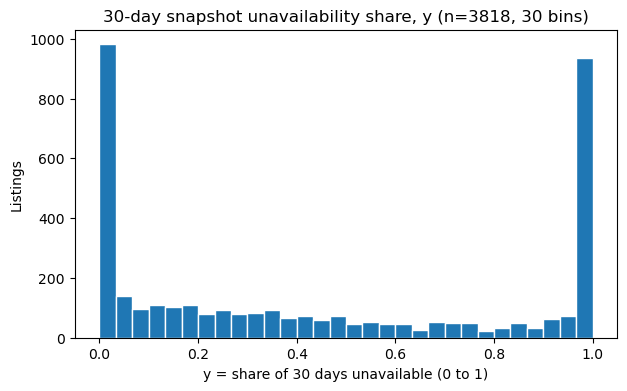

In [15]:
# target distribution, 30 bins because n >= 500, Week 2 Demo 2
n = len(df)
n_bins = 30 if n >= 500 else (20 if n >= 100 else 10)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["y"], bins=n_bins, edgecolor="white")
ax.set_title(f"30-day snapshot unavailability share, y (n={n}, {n_bins} bins)")
ax.set_xlabel("y = share of 30 days unavailable (0 to 1)")
ax.set_ylabel("Listings")
fig.savefig(FIG_DIR / "m01_target_distribution.png", dpi=110)
plt.show()

### M01 Findings
- 3,818 listings, one row each, `id` is unique.
- y runs 0 to 1 with nothing missing. Mean 0.44, median 0.33, SD 0.41.
- Every listing has exactly 30 calendar dates in the window, and `30 - availability_30` matches the calendar's unavailable count for all 3,818. The target checks out.
- The histogram is U-shaped. 981 listings are fully open and 883 are fully blocked. That large amount of listings at 0 and 1 is going to be the hard part for a regression model.

## M02 - Split, folds and mean reference
80/20 split with `random_state=42`, stratified on the four `walk_score` x `review_scores_rating` present/missing groups. Then 5 stratified folds inside train on the same groups. Same IDs and folds for everything after this. Test gets set aside here and I don't touch it until M06.2.

The course stratifies on the class label. y is continuous here, so the tracker stratifies on the missingness groups instead.

In [16]:
# the four missingness groups used for stratifying, tracker M02 
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df["group"] = (df["walk_score"].notna().map({True: "walk_present", False: "walk_missing"})
               + "|"
               + df["review_scores_rating"].notna().map({True: "rating_present", False: "rating_missing"}))

print("joint present/missing groups (all 3,818 listings):")
print(df["group"].value_counts().sort_index())

joint present/missing groups (all 3,818 listings):
group
walk_missing|rating_missing     193
walk_missing|rating_present     892
walk_present|rating_missing     454
walk_present|rating_present    2279
Name: count, dtype: int64


In [17]:
# 80/20 split stratified on the groups, test set aside, Week 3 Demo 1 
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["group"])
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_ids = train_df["id"].to_numpy()
test_ids = test_df["id"].to_numpy()

print("train:", len(train_df), "(expected 3054)   test:", len(test_df), "(expected 764)")
print("train and test IDs disjoint:", len(set(train_ids) & set(test_ids)) == 0)
print("train + test cover all listings:", set(train_ids) | set(test_ids) == set(df["id"]))
print()
print("group share (%) in all / train / test:")
share = pd.DataFrame({"all": df["group"].value_counts(normalize=True),
                      "train": train_df["group"].value_counts(normalize=True),
                      "test": test_df["group"].value_counts(normalize=True)}).mul(100).round(2)
print(share)

train: 3054 (expected 3054)   test: 764 (expected 764)
train and test IDs disjoint: True
train + test cover all listings: True

group share (%) in all / train / test:
                               all  train   test
group                                           
walk_present|rating_present  59.69  59.69  59.69
walk_missing|rating_present  23.36  23.38  23.30
walk_present|rating_missing  11.89  11.89  11.91
walk_missing|rating_missing   5.06   5.04   5.10


In [18]:
# 5 stratified folds inside train, reused for every model, Week 5 Lab 2 Part 1
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(skf.split(train_df, train_df["group"]))   # positional (train_idx, val_idx) on train_df

rows = []
for k, (tr, va) in enumerate(folds, start=1):
    row = {"fold": k, "n_fit": len(tr), "n_val": len(va)}
    row.update(train_df.iloc[va]["group"].value_counts().sort_index().to_dict())
    rows.append(row)
print("5 stratified folds on the 3,054 training listings (validation-group counts):")
print(pd.DataFrame(rows).set_index("fold"))

all_val = np.concatenate([va for _, va in folds])
print()
print("every training listing validated exactly once:", len(all_val) == len(train_df) and len(set(all_val)) == len(train_df))

5 stratified folds on the 3,054 training listings (validation-group counts):
      n_fit  n_val  walk_missing|rating_missing  walk_missing|rating_present  walk_present|rating_missing  walk_present|rating_present
fold                                                                                                                                  
1      2443    611                           31                          143                           72                          365
2      2443    611                           31                          143                           72                          365
3      2443    611                           31                          142                           73                          365
4      2443    611                           31                          143                           73                          364
5      2444    610                           30                          143                           73        

In [19]:
# mean reference: each fold predicts its own training mean, Week 3 Demo 1, Week 3 Lab 1, tracker M02 
def report(y_true, y_hat):
    return {"MAE": mean_absolute_error(y_true, y_hat),
            "RMSE": mean_squared_error(y_true, y_hat) ** 0.5,
            "R2": r2_score(y_true, y_hat)}

y_train = train_df["y"]

rows = []
for k, (tr, va) in enumerate(folds, start=1):
    ref = y_train.iloc[tr].mean()                       # this fold's training y only
    pred = np.full(len(va), ref)
    row = {"fold": k, "ref_mean": ref}
    row.update(report(y_train.iloc[va], pred))
    rows.append(row)
ref_table = pd.DataFrame(rows).set_index("fold")
print("Mean Prediction Reference, validation scores per fold:")
print(ref_table.round(4))
print()
print("mean across folds:")
print(ref_table[["MAE", "RMSE", "R2"]].mean().round(4))
print("sample SD across folds (ddof=1):")
print(ref_table[["MAE", "RMSE", "R2"]].std().round(4))

Mean Prediction Reference, validation scores per fold:
      ref_mean     MAE    RMSE      R2
fold                                  
1       0.4416  0.3625  0.3994 -0.0006
2       0.4376  0.3671  0.4038 -0.0006
3       0.4406  0.3767  0.4099 -0.0002
4       0.4388  0.3778  0.4112 -0.0001
5       0.4393  0.3743  0.4100 -0.0000

mean across folds:
MAE     0.3717
RMSE    0.4069
R2     -0.0003
dtype: float64
sample SD across folds (ddof=1):
MAE     0.0066
RMSE    0.0051
R2      0.0003
dtype: float64


### M02 Findings
- 3,054 train and 764 test, no overlap. Group shares match to within 0.1 points.
- Folds are 2,443/611. Every training listing gets validated once.
- Fold training means only move from 0.438 to 0.442, so the folds came out balanced on y too, even though I didn't stratify on y.
- Mean reference: RMSE 0.4069, MAE 0.3717, R2 about 0. That's the bar every model has to beat.
- R2 is slightly negative because each fold's training mean isn't exactly the validation mean.
- SD uses `ddof=1` like the tracker says. The labs used numpy `.std()` (`ddof=0`), so my SDs run a little bigger.

## M03 - Features inside a Pipeline
26 features from the tracker note plus `security_deposit_recorded`. `availability_*`, `y` and the raw `security_deposit` amount stay out.

- **18 numeric**: accommodates, bathrooms, bedrooms, beds, price, cleaning_fee, guests_included, extra_people, minimum_nights, maximum_nights, host_response_rate, calculated_host_listings_count, latitude, longitude, walk_score, number_of_reviews, reviews_per_month, review_scores_rating, median fill, then `StandardScaler`.
- **3 boolean**: instant_bookable, host_is_superhost, host_identity_verified, 0/1, mode fill, not scaled.
- **4 categorical**: room_type, property_type, cancellation_policy, neighbourhood_group_cleansed, mode fill, `OneHotEncoder(drop='first', handle_unknown='ignore')`.
- **1 categorical**: host_response_time | missing becomes `"Missing"`, same one-hot. 
- **5 flags**: cleaning_fee, host_response_rate, walk_score, reviews_per_month, review_scores_rating, `_was_missing` made before the fill, not scaled, derived, security_deposit_recorded, 1 if a deposit is recorded, else 0, not scaled.

The prediction date Jan 4, 2016 :

- In X, Listing and host fields, because snapshot values from Jan 4.
- In X, Review summaries, because reviews only go up to Jan 3.
- In X, Walk Score, neighborhood context, because 2016 vintage not verified.
- Not in X `availability_*`, calendar summaries, because that's the label window.

The `_was_missing` flags get made before the pipeline. No learning there, the median fill happens inside the pipeline.

`OneHotEncoder` fit inside each fold so validation and test categories don't leak into the fit, and that needs a `ColumnTransformer` to send each column group to its own steps.

In [20]:
# feature lists, was_missing flags, and the X matrix, Week 2 Demo 3, tracker M03 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import warnings

num_cols = ["accommodates", "bathrooms", "bedrooms", "beds", "price", "cleaning_fee",
            "guests_included", "extra_people", "minimum_nights", "maximum_nights",
            "host_response_rate", "calculated_host_listings_count", "latitude", "longitude",
            "walk_score", "number_of_reviews", "reviews_per_month", "review_scores_rating"]
bool_cols = ["instant_bookable", "host_is_superhost", "host_identity_verified"]
cat_mode_cols = ["room_type", "property_type", "cancellation_policy", "neighbourhood_group_cleansed"]
cat_missing_cols = ["host_response_time"]
ind_cols = ["cleaning_fee", "host_response_rate", "walk_score", "reviews_per_month", "review_scores_rating"]
flag_cols = [col + "_was_missing" for col in ind_cols]

print("source features:", len(num_cols) + len(bool_cols) + len(cat_mode_cols) + len(cat_missing_cols), "(expected 26)")

# review summaries must come from before the Jan 4, 2016 prediction time
print("latest last_review:", df["last_review"].max().date(),
      "| latest rev_last_date_from_reviews:", df["rev_last_date_from_reviews"].max().date())

def build_X(d):
    X = d[num_cols + bool_cols + cat_mode_cols + cat_missing_cols].copy()
    for col in num_cols + bool_cols:
        X[col] = d[col].to_numpy(dtype="float64", na_value=np.nan)   # pd.NA -> NaN, True/False -> 1/0
    for col in cat_mode_cols + cat_missing_cols:
        X[col] = d[col].astype(object).where(d[col].notna(), np.nan)
    # was_missing flags (no learning here), the median fill happens later inside the pipeline
    for col in ind_cols:
        X[col + "_was_missing"] = d[col].isna().astype(int)
    X["security_deposit_recorded"] = d["security_deposit"].notna().astype(float)
    return X

X_train = build_X(train_df)
print("X_train shape:", X_train.shape, "(26 source features + 5 flags + security_deposit_recorded = 32 columns)")

banned = [col for col in X_train.columns if col.startswith("availability") or col in ("y", "security_deposit", "group")]
print("leakage / target-derived columns found in X:", banned)
assert banned == []
print("rows aligned with y:", len(X_train) == len(y_train) and X_train.index.equals(y_train.index))

source features: 26 (expected 26)
latest last_review: 2016-01-03 | latest rev_last_date_from_reviews: 2016-01-03
X_train shape: (3054, 32) (26 source features + 5 flags + security_deposit_recorded = 32 columns)
leakage / target-derived columns found in X: []
rows aligned with y: True


In [23]:
# preprocessing, fit inside each training fold, Week 5 Lab 2 Part 2, ColumnTransformer and OneHotEncoder are tracker M03
def make_prep():
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
    bool_pipe = SimpleImputer(strategy="most_frequent")
    cat_mode_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))])
    cat_missing_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                                 ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num_cols),
                              ("bool", bool_pipe, bool_cols),
                              ("flag", "passthrough", flag_cols),
                              ("dep", "passthrough", ["security_deposit_recorded"]),
                              ("cat", cat_mode_pipe, cat_mode_cols),
                              ("cat_missing", cat_missing_pipe, cat_missing_cols)],
                             remainder="drop")

rows = []
for k, (tr, va) in enumerate(folds, start=1):
    prep = make_prep()
    Z_tr = prep.fit_transform(X_train.iloc[tr])          # fit on the fold's training rows only
    Z_va = prep.transform(X_train.iloc[va])
    names = prep.get_feature_names_out()
    rows.append({"fold": k, "Z_train_shape": Z_tr.shape, "Z_val_shape": Z_va.shape,
                 "n_features": len(names),
                 "rows_aligned": Z_tr.shape[0] == len(tr) and Z_va.shape[0] == len(va),
                 "all_finite": bool(np.isfinite(Z_tr).all() and np.isfinite(Z_va).all()),
                 "names_unique": len(set(names)) == len(names)})
print(pd.DataFrame(rows).set_index("fold"))
print()
print("columns prepared per fold (tracker says 65):", [r["n_features"] for r in rows])

     Z_train_shape Z_val_shape  n_features  rows_aligned  all_finite  names_unique
fold                                                                              
1       (2443, 65)   (611, 65)          65          True        True          True
2       (2443, 65)   (611, 65)          65          True        True          True
3       (2443, 65)   (611, 65)          65          True        True          True
4       (2443, 65)   (611, 65)          65          True        True          True
5       (2444, 65)   (610, 65)          65          True        True          True

columns prepared per fold (tracker says 65): [65, 65, 65, 65, 65]


In [24]:
# what the prepared columns look like (fold 1), tracker M03 (verify rows, finite values, feature names)
prep_demo = make_prep().fit(X_train.iloc[folds[0][0]])
names = prep_demo.get_feature_names_out()
print("feature names, fold 1 (", len(names), "):")
for i in range(0, len(names), 3):
    print("  " + " | ".join(names[i:i + 3]))

Z_demo = prep_demo.transform(X_train.iloc[folds[0][0]])
print()
print("scaled numeric block, fold-1 training rows: mean ~0, SD ~1 ->",
      round(Z_demo[:, :18].mean(), 4), "/", round(Z_demo[:, :18].std(), 4))
print("indicator block is 0/1 and unscaled:", sorted(set(np.unique(Z_demo[:, 21:26]))))
print("security_deposit_recorded block is 0/1 and unscaled:", sorted(set(np.unique(Z_demo[:, 26]))))

feature names, fold 1 ( 65 ):
  num__accommodates | num__bathrooms | num__bedrooms
  num__beds | num__price | num__cleaning_fee
  num__guests_included | num__extra_people | num__minimum_nights
  num__maximum_nights | num__host_response_rate | num__calculated_host_listings_count
  num__latitude | num__longitude | num__walk_score
  num__number_of_reviews | num__reviews_per_month | num__review_scores_rating
  bool__instant_bookable | bool__host_is_superhost | bool__host_identity_verified
  flag__cleaning_fee_was_missing | flag__host_response_rate_was_missing | flag__walk_score_was_missing
  flag__reviews_per_month_was_missing | flag__review_scores_rating_was_missing | dep__security_deposit_recorded
  cat__room_type_Private room | cat__room_type_Shared room | cat__property_type_Bed & Breakfast
  cat__property_type_Boat | cat__property_type_Bungalow | cat__property_type_Cabin
  cat__property_type_Camper/RV | cat__property_type_Chalet | cat__property_type_Condominium
  cat__property_type_Dor

### M03 Findings
- X_train is 3,054 x 32 with no leakage columns. Latest review date is Jan 3, 2016, so the review fields are from before the prediction date!
- Every fold comes out to 65 prepared columns, all finite, rows lined up, names unique. That matches the 65 in the tracker note.
- Scaled numerics sit at mean 0 / SD 1 on the training rows, and the flags and deposit column stay 0/1!